# Level 2 Task 4: Google Play Store Apps Analysis
**Oasis Infobyte Data Analytics Internship**

### Project Overview
This notebook performs an Exploratory Data Analysis (EDA) on the Android app market. The goal is to uncover market trends regarding app categories, user ratings, and monetization strategies.

### 1. Data Loading & Cleaning
The dataset requires cleaning before analysis:
* Removing malformed rows (e.g., ratings > 5.0).
* Stripping symbols (`+`, `,`, `$`) from `Installs` and `Price` columns to convert them to numeric types for mathematical analysis.

In [2]:
# Import standard libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('googleplaystore.csv')

# Display basic information
print(df.info())
print("\n--- First 5 Rows ---")
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB
None

--- First 5 Rows ---


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
# 1. Remove the corrupted row (which has a rating of 19.0)
corrupted_row = df[df['Rating'] == 19.0].index
df = df.drop(corrupted_row)

# 2. Clean 'Reviews' - Convert from string to integer
df['Reviews'] = df['Reviews'].astype(int)

# 3. Clean 'Installs' - Remove commas and plus signs, convert to integer
df['Installs'] = df['Installs'].str.replace('+', '', regex=False)
df['Installs'] = df['Installs'].str.replace(',', '', regex=False)
df['Installs'] = pd.to_numeric(df['Installs'])

# 4. Clean 'Price' - Remove dollar signs, convert to float
df['Price'] = df['Price'].str.replace('$', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'])

# 5. Check our work!
print(df[['Reviews', 'Installs', 'Price']].info())

<class 'pandas.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Reviews   10840 non-null  int64  
 1   Installs  10840 non-null  int64  
 2   Price     10840 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 338.8 KB
None


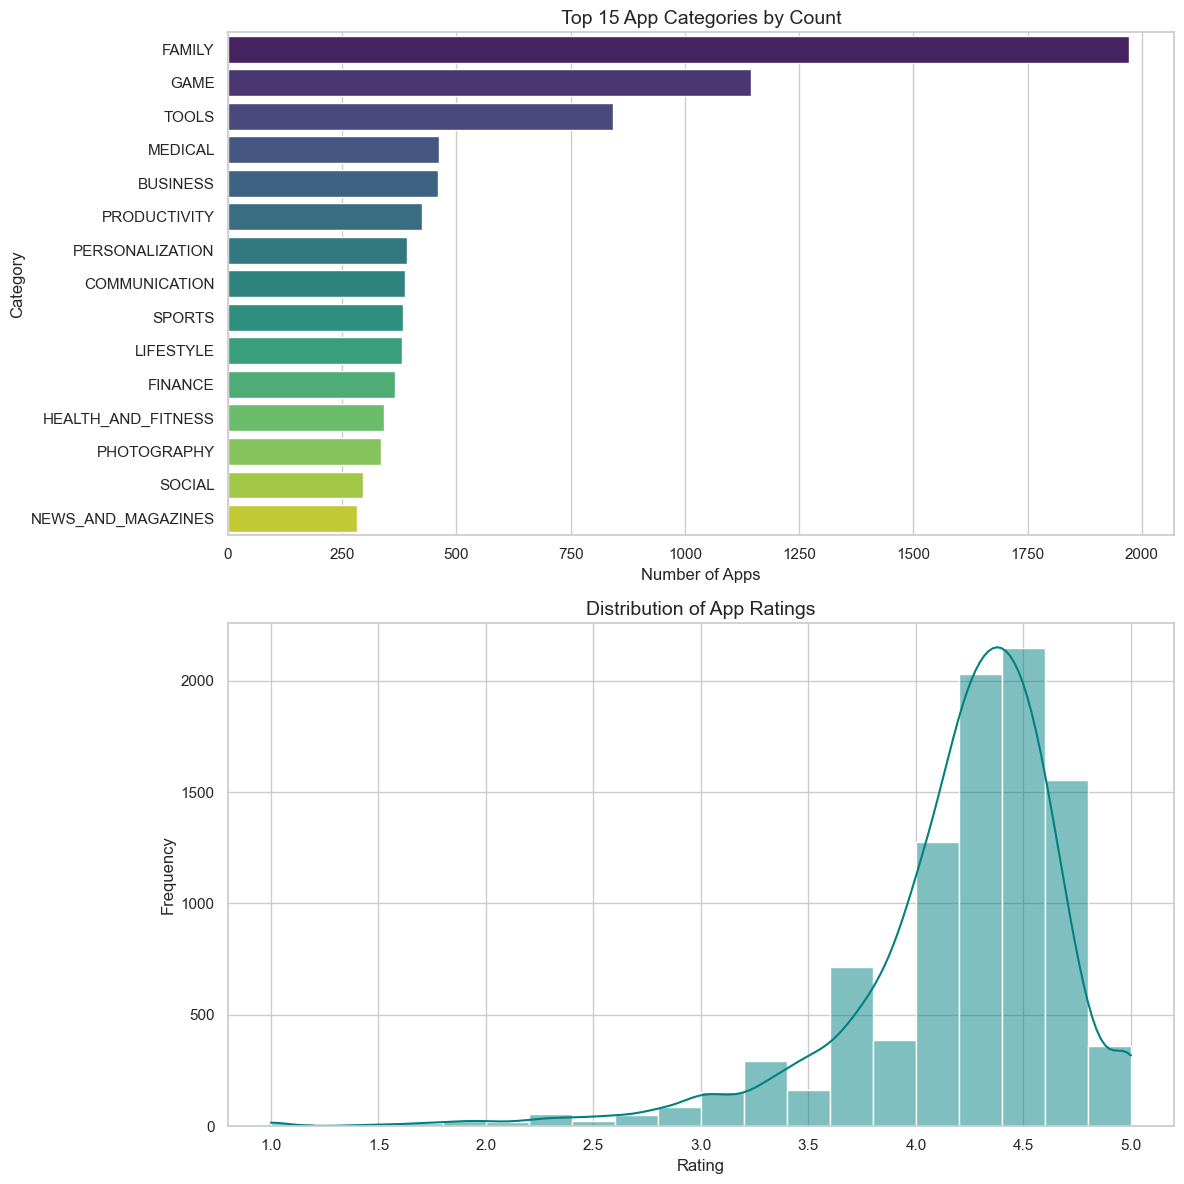

In [4]:
# Set the visual style for our charts
sns.set_theme(style="whitegrid")

# Create a figure with 2 subplots (stacked vertically)
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

# Chart 1: Top 15 App Categories by total number of apps
top_categories = df['Category'].value_counts().head(15)
sns.barplot(x=top_categories.values, y=top_categories.index, ax=axes[0], palette="viridis")
axes[0].set_title('Top 15 App Categories by Count', fontsize=14)
axes[0].set_xlabel('Number of Apps')
axes[0].set_ylabel('Category')

# Chart 2: Distribution of App Ratings
sns.histplot(df['Rating'].dropna(), bins=20, kde=True, ax=axes[1], color="teal")
axes[1].set_title('Distribution of App Ratings', fontsize=14)
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Frequency')

# Adjust layout and display
plt.tight_layout()
plt.show()

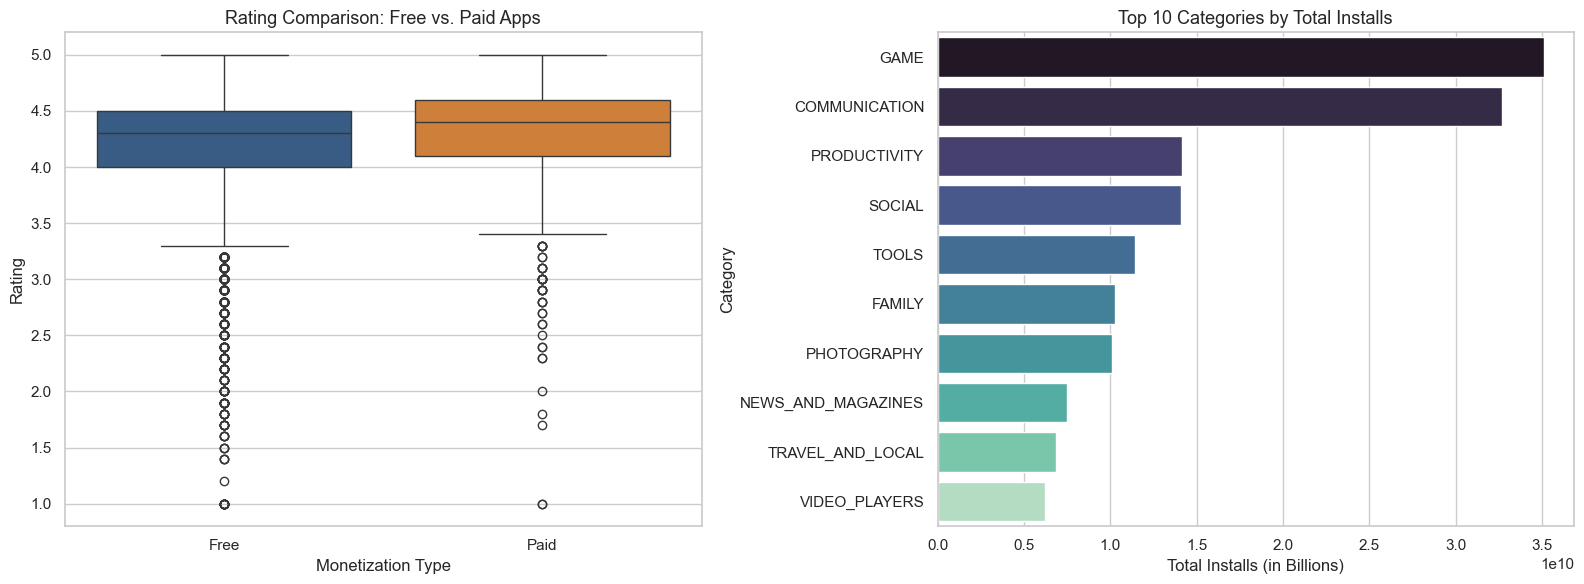

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot: Rating distribution between Free vs Paid apps
sns.boxplot(
    data=df.dropna(subset=['Type', 'Rating']),
    x='Type',
    y='Rating',
    palette=['#2b5c8f', '#e67e22'],
    ax=axes[0]
)
axes[0].set_title('Rating Comparison: Free vs. Paid Apps', fontsize=13)
axes[0].set_xlabel('Monetization Type')
axes[0].set_ylabel('Rating')

# 2. Total Installs across the Top 10 Categories
category_installs = (
    df.groupby('Category')['Installs']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

sns.barplot(
    data=category_installs,
    x='Installs',
    y='Category',
    palette='mako',
    ax=axes[1]
)
axes[1].set_title('Top 10 Categories by Total Installs', fontsize=13)
axes[1].set_xlabel('Total Installs (in Billions)')
axes[1].set_ylabel('Category')

plt.tight_layout()
plt.show()

### 3. Key Findings & Conclusion
* **Market Dominance:** `Family` and `Game` are the most saturated categories by volume, but `Game` and `Communication` apps drive the highest total installs.
* **User Sentiment:** App ratings are heavily left-skewed, indicating users generally leave positive feedback (peaking at 4.4).
* **Monetization Impact:** Paid apps maintain slightly higher median ratings with fewer extreme low-score outliers, suggesting a more premium, ad-free user experience.